In [1]:
import os
import glob
import numpy as np
import pandas as pd

from pybaselines import whittaker
import matplotlib.pyplot as plt

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg

In [64]:
def normalize_by_value(array, min_value=np.array([]), max_value=np.array([]), axis=1):

    if len(array.shape) == 2:
        if axis != 1:
            array = array.T
            transpose = True
        else:
            transpose = False
        if min_value.size == 0:
            min_value = np.min(array, 1)
        if max_value.size == 0:
            max_value = np.max(array, 1)
        diff = max_value - min_value
        if np.any(diff < 0):
            raise Exception("min_value > max_value")
        norm = (array - min_value[:, np.newaxis]) / diff[:, np.newaxis]

        if transpose:
            norm = norm.T

    elif len(array.shape) == 1:
        if min_value.size == 0:
            min_value = np.min(array)
        if max_value.size == 0:
            max_value = np.max(array)
        diff = max_value - min_value
        if diff < 0:
            raise Exception("min_value > max_value")

        norm = (array - min_value) / (diff)

    return norm


def snv_normalize(spectra, axis=0):
    """
    Standard Normal Variate (SNV) normalization.
    
    Centers each spectrum to zero mean and unit standard deviation.
    Useful for removing multiplicative scatter effects in spectroscopy.
    
    Parameters:
    -----------
    spectra : np.ndarray
        Array of spectra. If 2D, each column (axis=0) or row (axis=1) is a spectrum.
    axis : int
        Axis along which to normalize (0 for column-wise, 1 for row-wise)
    
    Returns:
    --------
    np.ndarray : SNV-normalized spectra
    """
    if len(spectra.shape) == 1:
        # Single spectrum
        mean = np.mean(spectra)
        std = np.std(spectra, ddof=1)
        if std == 0:
            return spectra - mean
        return (spectra - mean) / std
    
    elif len(spectra.shape) == 2:
        # Multiple spectra
        mean = np.mean(spectra, axis=axis, keepdims=True)
        std = np.std(spectra, axis=axis, ddof=1, keepdims=True)
        # Avoid division by zero
        std[std == 0] = 1
        return (spectra - mean) / std
    
    else:
        raise ValueError("Input must be 1D or 2D array")

def baseline_correct(spectrum, wavenumbers, lam=1e3, p=0.0001, niter=100, mode='als', eta=0.0005, show_plot=False):
    """
    Perform baseline correction using pybaselines (Asymmetric Least Squares or drPLS).
    
    Parameters:
    -----------
    spectrum : np.ndarray
        1D array of intensity values corresponding to the spectrum.
    wavenumbers : np.ndarray
        1D array of wavenumber values corresponding to the spectrum.
    lam : float
        Smoothness parameter (default: 1e4). Higher values make the baseline smoother.
    p : float
        Asymmetry parameter for 'als' (default: 0.0001).
    niter : int
        Number of iterations for the algorithm (default: 100).
    mode : str
        Algorithm to use: 'als' or 'drpls' (default: 'als').
    eta : float
        Smoothness parameter for 'drpls' (default: 0.05).
    show_plot : bool
        Whether to plot the results (default: False).
    
    Returns:
    --------
    np.ndarray : Baseline-corrected spectrum
    """
    
    # Ensure 1D to avoid broadcasting issues
    y = np.asanyarray(spectrum).flatten()
    
    if mode == 'als':
        # Asymmetric Least Squares
        baseline, _ = whittaker.asls(y, lam=lam, p=p, max_iter=niter)
    elif mode == 'drpls':
        # Dually Reweighted Penalized Least Squares
        baseline, _ = whittaker.drpls(y, lam=lam, eta=eta, max_iter=niter)
    else:
        raise ValueError(f"Unknown mode: {mode}. Use 'als' or 'drpls'.")

    corrected_spectrum = y - baseline

    if show_plot:
        plt.figure(figsize=(10, 4))
        plt.plot(wavenumbers, y, label='Original Spectrum', color='blue')    
        plt.plot(wavenumbers, baseline, label='Estimated Baseline', color='red', linestyle='--')
        plt.plot(wavenumbers, corrected_spectrum, label='Baseline-Corrected Spectrum', color='green')
        plt.title(f'Baseline Correction ({mode.upper()})')
        plt.legend()
        plt.show()

    return corrected_spectrum

def load_txt_folder_to_array(
    folder_dir,
    skip_first_column=True,
    remove_spectra=[],
    baseline_correction=True,
    show_plot=False,
    shift=0
):
    """
    Load .txt files for a condition into a dictionary with individual spectra
    and average/std summary curves. Supports a single folder path or list of folders.
    """
    if isinstance(folder_dir, (list, tuple)):
        files = []
        for d in folder_dir:
            files.extend(glob.glob(os.path.join(d, '*.txt')))
        files = sorted(files)
    else:
        print(folder_dir)
        files = sorted(glob.glob(os.path.join(folder_dir, '*.txt')))

    if not files:
        raise FileNotFoundError(f"No .txt files found in: {folder_dir}")

    first_data = np.loadtxt(files[0])
    if shift > 0:
        # Shift to the RIGHT (higher wavenumbers)
        ref_wavenumbers = first_data[shift:, 0]
    elif shift < 0:
        # Shift to the LEFT (lower wavenumbers)
        s = abs(shift)
        ref_wavenumbers = first_data[:-s, 0]
    else:
        ref_wavenumbers = first_data[:, 0]

    spectra_list = []
    filenames_list = []
    file_dict = {}

    for idx, file_path in enumerate(files):
        filename = os.path.basename(file_path)

        if idx in remove_spectra or filename in remove_spectra:
            continue

        temp = first_data if idx == 0 else np.loadtxt(file_path)
        if shift > 0:
            file_wavenumbers = temp[shift:, 0]
            file_spec = temp[:-shift, 1:]
        elif shift < 0:
            s = abs(shift)
            file_wavenumbers = temp[:-s, 0]
            file_spec = temp[s:, 1:]
        else:
            file_wavenumbers = temp[:, 0]
            file_spec = temp[:, 1:]


        # Interpolate if wavenumber grid differs
        if file_wavenumbers.shape[0] != ref_wavenumbers.shape[0] or not np.array_equal(file_wavenumbers, ref_wavenumbers):
            if file_spec.shape[1] == 1:
                interp_spec = np.interp(ref_wavenumbers, file_wavenumbers, file_spec.flatten())
                file_spec = interp_spec[:, np.newaxis]
            else:
                file_spec = np.column_stack([
                    np.interp(ref_wavenumbers, file_wavenumbers, file_spec[:, col])
                    for col in range(file_spec.shape[1])
                ])

        # Baseline correction
        if baseline_correction is not None and baseline_correction is not False:
            mode = baseline_correction if isinstance(baseline_correction, str) else 'als'
            if callable(baseline_correction):
                corrected = baseline_correction(file_spec, ref_wavenumbers)
            elif file_spec.shape[1] == 1:
                corrected = baseline_correct(file_spec.flatten(), ref_wavenumbers, mode=mode, show_plot=show_plot)
            else:
                corrected = np.column_stack([
                    baseline_correct(file_spec[:, col], ref_wavenumbers, mode=mode, show_plot=show_plot)
                    for col in range(file_spec.shape[1])
                ])
        else:
            corrected = file_spec

        corrected = corrected.squeeze()
        if corrected.ndim == 1:
            spectra_list.append(corrected)
            filenames_list.append(filename)
            file_dict[filename] = corrected
        else:
            for col in range(corrected.shape[1]):
                col_name = f"{filename}_col{col+1}"
                spectra_list.append(corrected[:, col])
                filenames_list.append(col_name)
                file_dict[col_name] = corrected[:, col]

    spectra_matrix = np.column_stack(spectra_list)
    mean_spectrum = np.mean(spectra_matrix, axis=1)
    median_spectrum = np.median(spectra_matrix, axis=1)
    std_spectrum = np.std(spectra_matrix, axis=1, ddof=1) if spectra_matrix.shape[1] > 1 else np.zeros_like(mean_spectrum)

    out = {
        'wavenumbers': ref_wavenumbers,
        'filenames': filenames_list,
        'spectra': spectra_matrix,
        'mean': mean_spectrum,
        'median': median_spectrum,
        'std': std_spectrum,
        'combined_array': np.column_stack([ref_wavenumbers, spectra_matrix]),
    }
    # Direct access by filename: out['sample_01.txt']
    out.update(file_dict)
    return out



def crop_and_normalize_region(base_directory, txt_arr, start_wavenumber, end_wavenumber, 
                              region_name="Region", plot=False, 
                              peak_labels=None, normalization='minmax'):
    """
    Crop and normalize spectra for a specific wavenumber region.
    
    Parameters:
    -----------
    base_directory : dir (str)
        Directory path for output
    txt_arr : np.ndarray
        Array with wavenumbers in first column and spectra in subsequent columns
    start_wavenumber : float
        Starting wavenumber for the region
    end_wavenumber : float
        Ending wavenumber for the region
    region_name : str
        Name of the region (e.g., "CH Stretching", "Fingerprint", "CD")
    plot : bool
        Whether to plot the normalized spectra
    peak_labels : dict
        Dictionary mapping wavenumber values (float or str) to peak labels
        Example: {2930: 'CH3', 2850: 'CH2', '1655': 'Amide I'}
    normalization : str
        Type of normalization: 'minmax' (default) or 'snv' (Standard Normal Variate)
    
    Returns:
    --------
    dict : Dictionary containing:
        - 'wavenumbers': wavenumber array for the region
        - 'normalized_spectra': normalized spectra array
        - 'cropped_array': original cropped array (wavenumbers + spectra)
    """
    # Find indices for cropping
    first_idx = np.argmin(np.abs(txt_arr[:, 0] - start_wavenumber))
    last_idx = np.argmin(np.abs(txt_arr[:, 0] - end_wavenumber))
    
    # Ensure proper ordering
    if first_idx > last_idx:
        first_idx, last_idx = last_idx, first_idx
    
    # Crop the array
    cropped_arr = txt_arr[first_idx:last_idx, :]
    wavenumbers = cropped_arr[:, 0]
    
    # Normalize spectra
    if normalization == 'snv':
        norm_arr_crop = snv_normalize(cropped_arr[:, 1:], axis=0)
    else:  # default to minmax
        norm_arr_crop = normalize_by_value(cropped_arr[:, 1:], axis=0)
    
    # Plot if requested
    if plot:
        plt.figure(figsize=(10, 6))
        for idx, arr in enumerate(norm_arr_crop.T):
            plt.plot(wavenumbers, arr, label=f'Spectra {idx+1}')
        
        # Get current y-axis limits
        y_min, y_max = plt.ylim()
        y_range = y_max - y_min
        
        # Add peak labels if provided
        if peak_labels:
            max_label_height = 0
            for wavenumber, label in peak_labels.items():
                wn = float(wavenumber)
                # Find closest wavenumber in the region
                if start_wavenumber <= wn <= end_wavenumber or end_wavenumber <= wn <= start_wavenumber:
                    wn_idx = np.argmin(np.abs(wavenumbers - wn))
                    # Get max intensity at this wavenumber
                    max_intensity = np.max(norm_arr_crop[wn_idx, :])
                    max_label_height = max(max_label_height, max_intensity)
                    
                    plt.axvline(x=wn, color='gray', linestyle='--', alpha=0.5, zorder=1)
            
            # Extend y-axis if labels would be too close to the top
            # Reserve 20% of the plot height for labels
            if max_label_height > y_max - 0.2 * y_range:
                new_y_max = max_label_height + 0.4 * y_range
                plt.ylim(y_min, new_y_max)
                y_max = new_y_max
                y_range = y_max - y_min
            
            # Now add text labels with updated margins
            for wavenumber, label in peak_labels.items():
                wn = float(wavenumber)
                if start_wavenumber <= wn <= end_wavenumber or end_wavenumber <= wn <= start_wavenumber:
                    wn_idx = np.argmin(np.abs(wavenumbers - wn))
                    max_intensity = np.max(norm_arr_crop[wn_idx, :])
                    # Position text above the highest peak with padding
                    text_y = max_intensity + 0.05 * y_range
                    
                    plt.text(wn, text_y, label, 
                            rotation=90, verticalalignment='bottom', horizontalalignment='center',
                            fontsize=11, fontweight='bold', alpha=1.0,
                            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                     edgecolor='gray', alpha=0.9, linewidth=0.5),
                            zorder=5, clip_on=True)
        
        plt.xlabel('Wavenumber (cm$^{-1}$)')
        plt.ylabel('Normalized Intensity (A.U.)')
        plt.title(f"{region_name}")
        plt.legend().set_visible(True)
        plt.tight_layout()
        
        # Save figure to base directory
        safe_filename = region_name.replace(' ', '_').replace('/', '_').replace('\\', '_') + '.png'
        save_path = os.path.join(base_directory, "images", safe_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
        
        plt.show()
    
    return {
        'wavenumbers': wavenumbers,
        'normalized_spectra': norm_arr_crop,
        'cropped_array': cropped_arr
    }



def crop_and_normalize_region(
    data, 
    start_wavenumber, 
    end_wavenumber, 
    region_name="Region", 
    plot=False, 
    peak_labels=None, 
    normalization='minmax',
    show_std=True,
    plot_individual=False,
    save_dir=None
):
    """
    Crop and normalize spectra for a specific wavenumber region.
    Supports either a single condition (2D array or dict) or multiple conditions (dict of dicts/arrays).
    """
    # Detect if data is a multi-condition dict or a single condition
    is_multi_condition = (
        isinstance(data, dict) and 
        'wavenumbers' not in data and 
        all(isinstance(v, (dict, np.ndarray)) for v in data.values())
    )

    condition_dict = data if is_multi_condition else {"Condition": data}
    processed_conditions = {}
    ref_cropped_wn = None

    for cond_name, cond_val in condition_dict.items():
        if isinstance(cond_val, dict):
            wn = cond_val['wavenumbers']
            spec = cond_val['spectra']
            fnames = cond_val.get('filenames', [f"Spec_{i+1}" for i in range(spec.shape[1])])
        else:
            wn = cond_val[:, 0]
            spec = cond_val[:, 1:]
            fnames = [f"Spec_{i+1}" for i in range(spec.shape[1])]

        first_idx = np.argmin(np.abs(wn - start_wavenumber))
        last_idx = np.argmin(np.abs(wn - end_wavenumber))
        if first_idx > last_idx:
            first_idx, last_idx = last_idx, first_idx

        cropped_wn = wn[first_idx:last_idx]
        cropped_spec = spec[first_idx:last_idx, :]

        if ref_cropped_wn is None:
            ref_cropped_wn = cropped_wn

        # Normalize in region
        if normalization == 'snv':
            norm_spec = snv_normalize(cropped_spec, axis=0)
        else:
            norm_spec = normalize_by_value(cropped_spec, axis=0)

        mean_spec = np.mean(norm_spec, axis=1)
        median_spec = np.median(norm_spec, axis=1)
        std_spec = np.std(norm_spec, axis=1, ddof=1) if norm_spec.shape[1] > 1 else np.zeros_like(mean_spec)

        processed_conditions[cond_name] = {
            'wavenumbers': cropped_wn,
            'normalized_spectra': norm_spec,
            'mean': mean_spec,
            'median': median_spec,
            'std': std_spec,
            'filenames': fnames
        }

    if plot:
        fig, ax = plt.subplots(figsize=(6, 6))
        palette = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b', '#e377c2']
        all_max_heights = []

        spec_add = 0

        for c_idx, (cond_name, c_data) in enumerate(processed_conditions.items()):
            color = palette[c_idx % len(palette)]
            wn = c_data['wavenumbers']
            norm_spec = c_data['normalized_spectra']
            mean_spec = c_data['mean']
            std_spec = c_data['std']
            n_samples = norm_spec.shape[1]

            mean_spec += spec_add
            # std_spec += spec_add

            if not is_multi_condition:
                for s_idx in range(n_samples):
                    label = fnames[s_idx] if s_idx < len(fnames) else f'Spectra {s_idx+1}'
                    ax.plot(wn, norm_spec[:, s_idx], label=label, alpha=0.7)
                all_max_heights.append(np.max(norm_spec))
            else:
                if plot_individual:
                    for s_idx in range(n_samples):
                        ax.plot(wn, norm_spec[:, s_idx], color=color, alpha=0.2, linewidth=0.8)

                ax.plot(wn, mean_spec, color=color, linewidth=2.2, label=f"{cond_name} (n={n_samples})")


                if show_std and n_samples > 1:
                    ax.fill_between(wn, mean_spec - std_spec, mean_spec + std_spec, color=color, alpha=0.2)
                    all_max_heights.append(np.max(mean_spec + std_spec))
                else:
                    all_max_heights.append(np.max(mean_spec))
            spec_add += 3

        # Peak Labels positioned above all conditions
        if peak_labels and len(all_max_heights) > 0:
            y_min, y_max = ax.get_ylim()
            y_range = y_max - y_min
            max_label_height = 0

            for wavenumber, label in peak_labels.items():
                w_val = float(wavenumber)
                min_w = min(start_wavenumber, end_wavenumber)
                max_w = max(start_wavenumber, end_wavenumber)
                if min_w <= w_val <= max_w:
                    wn_idx = np.argmin(np.abs(ref_cropped_wn - w_val))
                    local_max = max(c['mean'][wn_idx] + (c['std'][wn_idx] if show_std else 0) for c in processed_conditions.values())
                    max_label_height = max(max_label_height, local_max)
                    ax.axvline(x=w_val, color='gray', linestyle='--', alpha=0.5, zorder=1)

            if max_label_height > y_max - 0.2 * y_range:
                new_y_max = max_label_height + 0.4 * y_range
                ax.set_ylim(y_min, new_y_max)
                y_max = new_y_max
                y_range = y_max - y_min

            for wavenumber, label in peak_labels.items():
                w_val = float(wavenumber)
                min_w = min(start_wavenumber, end_wavenumber)
                max_w = max(start_wavenumber, end_wavenumber)
                if min_w <= w_val <= max_w:
                    wn_idx = np.argmin(np.abs(ref_cropped_wn - w_val))
                    local_max = max(c['mean'][wn_idx] + (c['std'][wn_idx] if show_std else 0) for c in processed_conditions.values())
                    text_y = local_max + 0.05 * y_range
                    ax.text(
                        w_val, text_y, label,
                        rotation=90, verticalalignment='bottom', horizontalalignment='center',
                        fontsize=10, fontweight='bold', alpha=0.9,
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9, linewidth=0.5),
                        zorder=5, clip_on=True
                    )

        ax.set_xlabel(r'Wavenumber (cm$^{-1}$)', fontsize=12, fontweight='bold')
        ax.set_ylabel(f'Normalized Intensity ({normalization.capitalize()})', fontsize=12, fontweight='bold')
        ax.set_title(f"{region_name}", fontsize=14, fontweight='bold')
        ax.legend(loc='best')
        plt.tight_layout()

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            safe_filename = region_name.replace(' ', '_').replace('/', '_').replace('\\', '_') + '.png'
            save_path = os.path.join(save_dir, safe_filename)
            plt.savefig(save_path, dpi=300, bbox_inches='tight', transparent='True')
            print(f"Saved: {save_path}")

        plt.show()

    if not is_multi_condition:
        c_first = list(processed_conditions.values())[0]
        return {
            'wavenumbers': c_first['wavenumbers'],
            'normalized_spectra': c_first['normalized_spectra'],
            'cropped_array': np.column_stack([c_first['wavenumbers'], c_first['normalized_spectra']]),
            'mean': c_first['mean'],
            'std': c_first['std']
        }
    else:
        return {
            'wavenumbers': ref_cropped_wn,
            'conditions': processed_conditions
        }



def get_peak_intensity(wavenumbers, spectrum, peak_wn, window=5):
    """
    Get peak intensity at peak_wn. If window > 0, finds the maximum within peak_wn +/- window.
    """
    if window > 0:
        mask = (wavenumbers >= peak_wn - window) & (wavenumbers <= peak_wn + window)
        if np.any(mask):
            return np.max(spectrum[mask])
    idx = np.argmin(np.abs(wavenumbers - peak_wn))
    return spectrum[idx]


def calculate_peak_ratio(
    data,
    peak_a,
    peak_b,
    peak_labels=None,
    window=5,
    plot=True,
    show_ns=False,
    save_path=None
):
    """
    Calculate Peak A / (Peak A + Peak B) for every spectrum before normalization.
    Performs Welch's ANOVA and Games-Howell post-hoc with pingouin, and plots a
    bar plot with overlapping mean labels, individual data points, and significance bars.

    Parameters:
    -----------
    data : dict or np.ndarray
        Single condition dict, multi-condition dict ({"Day 4": d4, "Day 5": d5}),
        or 2D numpy array [wavenumbers, spectra...].
    peak_a : float or str
        Wavenumber or label for Peak A.
    peak_b : float or str
        Wavenumber or label for Peak B.
    peak_labels : dict, optional
        Dictionary mapping wavenumber values to peak labels (e.g., {2850: 'CH2 sym'}).
    window : float
        Search window in cm^-1 to locate the local peak maximum (default: 5).
    plot : bool
        Whether to generate the bar plot with significance bars.
    show_ns : bool
        Whether to show 'ns' brackets for non-significant comparisons (default: False).
    save_path : str, optional
        File path to save the generated plot.

    Returns:
    --------
    df : pd.DataFrame
        DataFrame with individual spectra ratios and intensities.
    summary : pd.DataFrame
        Summary statistics (Count, Mean, Std, Median) grouped by condition.
    aov : pd.DataFrame
        Welch's ANOVA results table.
    posthoc : pd.DataFrame
        Games-Howell post-hoc pairwise comparison table.
    """
    # 1. Resolve peak labels to numeric wavenumbers
    def resolve_wn(peak, labels):
        if isinstance(peak, (int, float)):
            return float(peak), f"{peak:.0f} cm⁻¹"
        if labels:
            for wn_val, lbl in labels.items():
                if str(lbl).strip().lower() == str(peak).strip().lower():
                    return float(wn_val), str(lbl)
        try:
            return float(peak), f"{float(peak):.0f} cm⁻¹"
        except ValueError:
            raise ValueError(f"Could not resolve peak '{peak}'. Check peak_labels dictionary.")

    wn_a, name_a = resolve_wn(peak_a, peak_labels)
    wn_b, name_b = resolve_wn(peak_b, peak_labels)

    # Detect multi-condition vs single condition
    is_multi_condition = (
        isinstance(data, dict) and
        'wavenumbers' not in data and
        all(isinstance(v, (dict, np.ndarray)) for v in data.values())
    )

    condition_dict = data if is_multi_condition else {"Condition": data}
    records = []

    # 2. Extract un-normalized peak intensities & compute ratios
    for cond_name, cond_val in condition_dict.items():
        if isinstance(cond_val, dict):
            wn = cond_val['wavenumbers']
            spec_mat = cond_val['spectra']  # 2D array before normalization
            fnames = cond_val.get('filenames', [f"Spec_{i+1}" for i in range(spec_mat.shape[1])])
        else:
            wn = cond_val[:, 0]
            spec_mat = cond_val[:, 1:]
            fnames = [f"Spec_{i+1}" for i in range(spec_mat.shape[1])]

        n_samples = spec_mat.shape[1]
        for s_idx in range(n_samples):
            spectrum = spec_mat[:, s_idx]
            int_a = get_peak_intensity(wn, spectrum, wn_a, window=window)
            int_b = get_peak_intensity(wn, spectrum, wn_b, window=window)

            denom = int_a + int_b
            ratio = (int_a / denom) if denom != 0 else np.nan

            records.append({
                'Condition': cond_name,
                'Filename': fnames[s_idx] if s_idx < len(fnames) else f"Spec_{s_idx+1}",
                f'Intensity_{name_a}': int_a,
                f'Intensity_{name_b}': int_b,
                'Ratio': ratio
            })

    df = pd.DataFrame(records)
    conditions = df['Condition'].unique()
    n_cond = len(conditions)

    # 3. Summary statistics
    summary = df.groupby('Condition')['Ratio'].agg(
        Count='count',
        Mean='mean',
        Std='std',
        Median='median'
    ).reindex(conditions).reset_index()

    # 4. Statistical Tests with pingouin
    aov = None
    posthoc = None
    if n_cond >= 2 and len(df.dropna(subset=['Ratio'])) > n_cond:
        try:
            aov = pg.welch_anova(data=df, dv='Ratio', between='Condition')
        except Exception as e:
            print(f"Welch's ANOVA note: {e}")

        try:
            posthoc = pg.pairwise_gameshowell(data=df, dv='Ratio', between='Condition')
        except Exception as e:
            print(f"Games-Howell post-hoc note: {e}")

    # 5. Plotting: Barplot + Mean Text + Jittered Dots + Significance Brackets
    if plot and len(df) > 0:
        fig, ax = plt.subplots(figsize=(8, 6.5))
        palette = ['#4A90E2', '#E74C3C', '#2ECC71', '#9B59B6', '#F39C12', '#1ABC9C']

        x_positions = np.arange(n_cond)
        means = summary['Mean'].values
        stds = summary['Std'].fillna(0).values

        # Bar plot
        bars = ax.bar(
            x_positions,
            means,
            yerr=stds,
            capsize=6,
            color=[palette[i % len(palette)] for i in range(n_cond)],
            alpha=0.75,
            edgecolor='black',
            linewidth=1.2,
            width=0.55,
            zorder=2
        )

        # Overlay individual points and mean text label
        for idx, cond in enumerate(conditions):
            vals = df[df['Condition'] == cond]['Ratio'].dropna().values
            jitter = np.random.normal(0, 0.035, size=len(vals))

            # Individual sample points
            ax.scatter(
                x_positions[idx] + jitter,
                vals,
                color='black',
                alpha=0.65,
                s=40,
                edgecolors='white',
                linewidths=0.6,
                zorder=3
            )

            # Mean text label positioned in the center of the bar
            mean_val = means[idx]
            std_val = stds[idx]
            label_y = mean_val * 0.5
            ax.text(
                x_positions[idx],
                label_y,
                f"Mean: {mean_val:.3f}\n± {std_val:.3f}",
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='white',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='black', alpha=0.45, edgecolor='none'),
                zorder=4
            )

        # Significance Brackets (Games-Howell)
        max_data_val = max(df['Ratio'].max(), np.max(means + stds))
        y_range = max_data_val - min(0, df['Ratio'].min())
        step = 0.09 * y_range
        tick_h = 0.02 * y_range
        current_y = max_data_val + 0.06 * y_range

        if posthoc is not None and len(posthoc) > 0:
            cond_to_x = {c: x for x, c in zip(x_positions, conditions)}
            comps = posthoc.copy()
            if not show_ns:
                comps = comps[comps['pval'] < 0.05]

            for _, row in comps.iterrows():
                x1 = cond_to_x[row['A']]
                x2 = cond_to_x[row['B']]
                if x1 > x2:
                    x1, x2 = x2, x1

                p = row['pval']
                if p < 0.001:
                    stars = '***'
                elif p < 0.01:
                    stars = '**'
                elif p < 0.05:
                    stars = '*'
                else:
                    stars = 'ns'

                # Draw horizontal bracket with vertical ticks
                ax.plot([x1, x1, x2, x2],
                        [current_y - tick_h, current_y, current_y, current_y - tick_h],
                        color='black', lw=1.3, zorder=5)

                # Annotation text
                ax.text(
                    (x1 + x2) / 2,
                    current_y + 0.005 * y_range,
                    stars,
                    ha='center',
                    va='bottom',
                    fontsize=12,
                    fontweight='bold',
                    color='black',
                    zorder=5
                )
                current_y += step

        # Axes labels & Title
        ax.set_xticks(x_positions)
        ax.set_xticklabels(conditions, fontsize=12, fontweight='bold')
        ax.set_ylabel(f"Ratio: {name_a} / ({name_a} + {name_b})", fontsize=12, fontweight='bold')

        title_str = f"Peak Ratio: {name_a} vs {name_b}"
        if aov is not None and not aov.empty:
            p_col = 'p_unc' if 'p_unc' in aov.columns else 'p-unc'
            p_val = aov[p_col].values[0]
            title_str += f"\n(Welch's ANOVA p = {p_val:.2e}, Games-Howell post-hoc)"
        ax.set_title(title_str, fontsize=13, fontweight='bold')

        ax.set_ylim(bottom=0, top=current_y + 0.04 * y_range)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved ratio plot: {save_path}")

        plt.show()

    return df, summary, aov, posthoc

In [65]:
condition_folder = r"/Users/jorgevillazon/Downloads/cancer_exosome (1) 2/08-02-24 COLO205 EXOSOME"

data = load_txt_folder_to_array(condition_folder, baseline_correction=False, shift=0)

/Users/jorgevillazon/Downloads/cancer_exosome (1) 2/08-02-24 COLO205 EXOSOME


In [66]:
import pandas as pd
exosome_dict = {
'A375': r"/Users/jorgevillazon/Documents/GitHub/exosome_spectra/cancer_exosome/Normalized Spectra/A375.csv",
'COLO205': r"/Users/jorgevillazon/Documents/GitHub/exosome_spectra/cancer_exosome/Normalized Spectra/COLO205.csv",
'LNCaP' : r"/Users/jorgevillazon/Documents/GitHub/exosome_spectra/cancer_exosome/Normalized Spectra/LNCaP.csv"
}

In [67]:
import pandas as pd
import numpy as np

def load_csv_spectra(csv_path, condition_name="Sample"):
    df = pd.read_csv(csv_path)
    
    # 1st column is wavenumbers, remaining columns are spectra
    wavenumbers = df.iloc[:, 0].to_numpy(dtype=float)
    spectra = df.iloc[:, 1:].to_numpy(dtype=float)
    filenames = [str(col) for col in df.columns[1:]]
    
    return {
        'wavenumbers': wavenumbers,
        'spectra': spectra,
        'filenames': filenames
    }


In [68]:
exosome_data = {}
for name, path in exosome_dict.items():
    df = pd.read_csv(path)
    wavenumbers = df['Wavenumber']
    spectra = df.iloc[:, 1:].to_numpy(dtype=float)
    filenames = [str(col) for col in df.columns[1:]]
    exosome_data[name] = {
        'wavenumbers': wavenumbers,
        'spectra': spectra,
        'filenames': filenames
    }
    

Saved: /Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir/Fingerprint.png


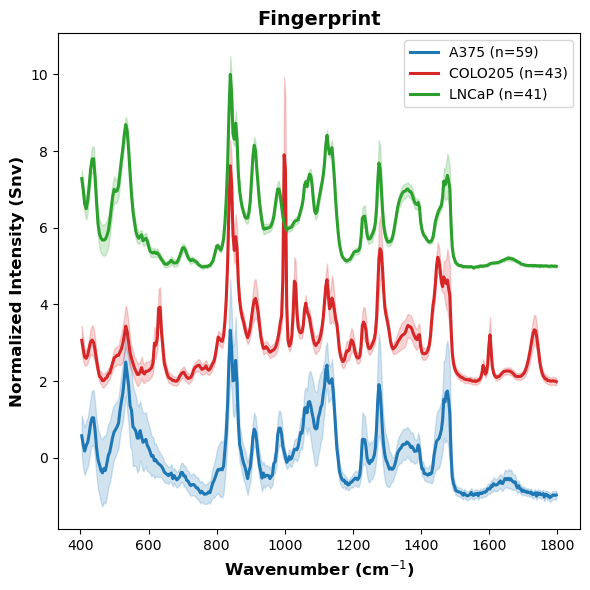

Saved: /Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir/CH_Region.png


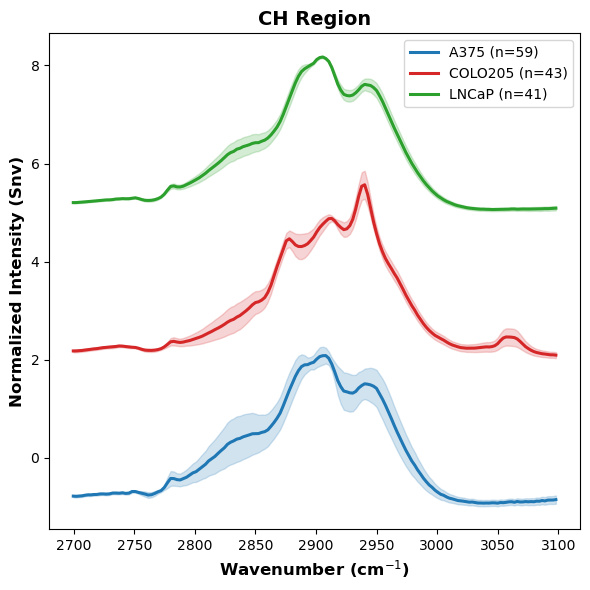

Saved: /Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir/Whole_Spectra.png


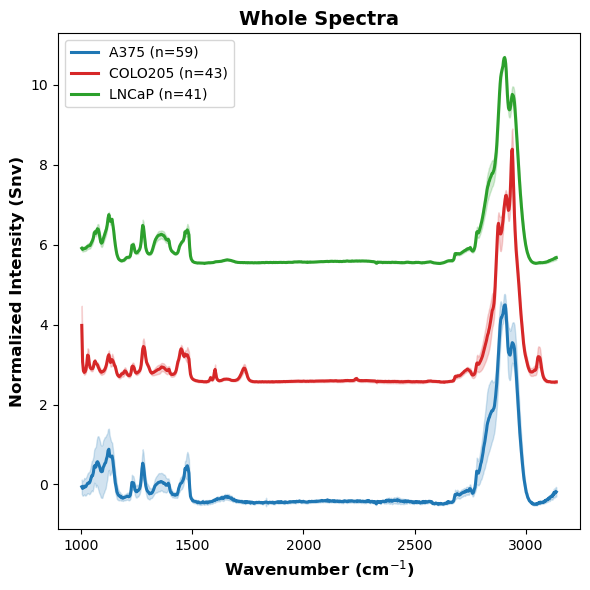

{'wavenumbers': 147    1001.52
 148    1005.29
 149    1009.05
 150    1012.80
 151    1016.56
         ...   
 869    3129.39
 870    3131.61
 871    3133.82
 872    3136.03
 873    3138.24
 Name: Wavenumber, Length: 727, dtype: float64,
 'conditions': {'A375': {'wavenumbers': 147    1001.52
   148    1005.29
   149    1009.05
   150    1012.80
   151    1016.56
           ...   
   869    3129.39
   870    3131.61
   871    3133.82
   872    3136.03
   873    3138.24
   Name: Wavenumber, Length: 727, dtype: float64,
   'normalized_spectra': array([[-0.15532607, -0.17617966, -0.24920957, ..., -0.11121649,
           -0.14385571, -0.13097433],
          [-0.24010512, -0.23850215, -0.30475606, ..., -0.18684421,
           -0.1723133 , -0.17013366],
          [-0.22637821, -0.21052988, -0.31887765, ..., -0.17653443,
           -0.12520203, -0.11950304],
          ...,
          [-0.14510294, -0.18981712, -0.33606201, ..., -0.1797429 ,
           -0.30022911, -0.13506682],
          [-0.1

In [73]:
crop_and_normalize_region(
    exosome_data,
    start_wavenumber=400,
    end_wavenumber=1800,
    region_name="Fingerprint",
    plot=True,
    # peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir = r"/Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir"
)


crop_and_normalize_region(
    exosome_data,
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="CH Region",
    plot=True,
    # peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir = r"/Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir"
)



crop_and_normalize_region(
    exosome_data,
    start_wavenumber=1000,
    end_wavenumber=3140,
    region_name="Whole Spectra",
    plot=True,
    # peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir = r"/Users/jorgevillazon/Downloads/cancer_exosome (1) 2/output_dir"
)

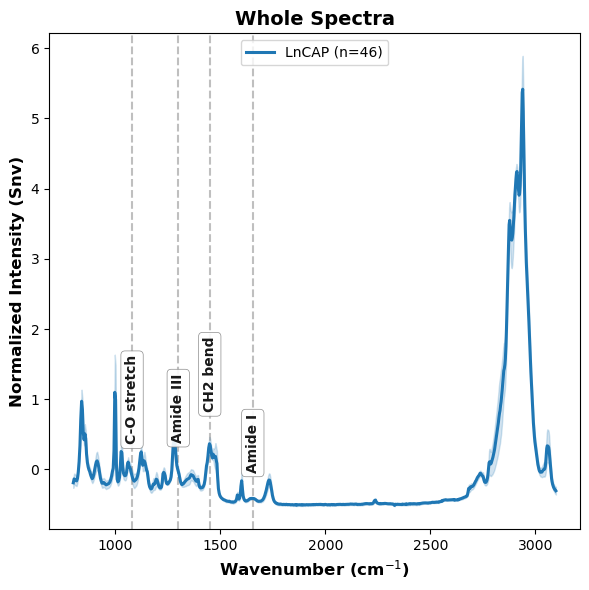

{'wavenumbers': array([ 800.151,  804.126,  808.098,  812.067,  816.031,  819.991,
         823.95 ,  827.902,  831.85 ,  835.793,  839.735,  843.669,
         847.601,  851.528,  855.452,  859.372,  863.287,  867.197,
         871.106,  875.008,  878.909,  882.803,  886.692,  890.58 ,
         894.465,  898.342,  902.217,  906.086,  909.952,  913.815,
         917.673,  921.529,  925.378,  929.226,  933.066,  936.903,
         940.736,  944.568,  948.394,  952.216,  956.031,  959.847,
         963.655,  967.459,  971.262,  975.059,  978.85 ,  982.64 ,
         986.425,  990.206,  993.982,  997.756, 1001.52 , 1005.29 ,
        1009.05 , 1012.8  , 1016.56 , 1020.3  , 1024.05 , 1027.79 ,
        1031.52 , 1035.26 , 1038.98 , 1042.71 , 1046.43 , 1050.14 ,
        1053.85 , 1057.56 , 1061.26 , 1064.96 , 1068.66 , 1072.35 ,
        1076.04 , 1079.72 , 1083.4  , 1087.07 , 1090.74 , 1094.41 ,
        1098.07 , 1101.73 , 1105.38 , 1109.03 , 1112.68 , 1116.32 ,
        1119.96 , 1123.59 , 1127.

In [70]:
# Define peak labels for different regions
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym', 
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

fingerprint_peaks = {
    1655: 'Amide I',
    1450: 'CH2 bend',
    1300: 'Amide III',
    1080: 'C-O stretch'
}

cd_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein'
}

crop_and_normalize_region(
    {"LnCAP":data},
    start_wavenumber=800,
    end_wavenumber=3100,
    region_name="Whole Spectra",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
)

In [17]:
conditions_folders = {
    "Day 4": [
        r"E:\11-07-25 Embryo 10 Day 4",
        r"E:\11-07-25 Embryo 11 Day 4",
    ],
    "Day 5": [
        r"E:\11-11-25 Embryo 14 Day 5",
        r"E:\11-11-25 Embryo 16 Day 5",
    ],
}
output_images_dir = r"E:\Embryo Day 4 vs Day 5\images"

conditions_data = {}
for cond_name, folder_paths in conditions_folders.items():
    print(f"Loading {cond_name}...")
    conditions_data[cond_name] = load_txt_folder_to_array(folder_paths, baseline_correction=True)

# Choose normalization method: 'minmax' or 'snv'
full_spectrum_normalization = 'snv'  # Change to 'minmax' for min-max normalization

# Define peak labels for different regions
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym', 
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

fingerprint_peaks = {
    1655: 'Amide I',
    1450: 'CH2 bend',
    1300: 'Amide III',
    1080: 'C-O stretch'
}

cd_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein'
}

# Compare conditions in the CH Stretching region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="Embryo Day 4 vs Day 5 - CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,          # Shaded +/- 1 SD band
    plot_individual=False,  # Set to True to also show faint individual lines
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=800,
    end_wavenumber=1800,
    region_name="Embryo Day 4 vs Day 5 - Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="Embryo Day 4 vs Day 5 - CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)


Loading Day 4...


FileNotFoundError: No .txt files found in: ['E:\\11-07-25 Embryo 10 Day 4', 'E:\\11-07-25 Embryo 11 Day 4']